In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import normalize , LabelEncoder
from sklearn.model_selection import train_test_split, KFold
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense, Dropout, Activation, Input
from tensorflow.keras.models import Model, Sequential
from keras.regularizers import l2
from keras.callbacks import EarlyStopping
import xgboost as xgb
from functions import *

np.random.seed(111)
tf.random.set_seed(111)


In [2]:
kf = KFold(n_splits=5, shuffle=True, random_state=111)

In [3]:
# data read and types check
df = pd.read_csv('https://raw.githubusercontent.com/paq88/Deep-Learning-in-classification-of-common-Carp-intestine-classification/refs/heads/main/Data/Gut_bacteria_merged.csv')
print(df.shape)
print(df.dtypes)
df.head()

(124, 127)
pond                                                                                           object
d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae             float64
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae       float64
d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae                    float64
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae                    float64
                                                                                               ...   
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae           float64
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae      float64
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae           float64
d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df = df.fillna(0)
df.head()

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
print(df.shape)
df.describe()

(124, 127)


,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,...,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,831.653226,8693.169355,171.370968,71.137097,105.548387,196.209677,677.419355,375.854839,53.169355,25.241935,...,0.096774,0.298387,0.080645,2.153226,0.217742,1.604839,0.153226,0.096774,0.266129,0.185484
std,1120.105607,5604.123141,224.484829,146.755443,192.490201,637.902078,2845.964849,456.780652,98.483354,67.552253,...,1.077632,2.270274,0.898027,20.938565,2.093585,13.805159,1.706250,1.077632,2.537872,2.065461
min,0.000000,167.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,106.750000,3913.500000,37.750000,0.000000,0.000000,6.750000,0.000000,55.500000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,469.500000,7454.500000,105.500000,2.000000,13.500000,27.500000,0.000000,211.000000,4.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1037.750000,12774.000000,241.000000,91.500000,131.000000,118.250000,48.750000,467.250000,62.250000,15.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,6597.000000,26160.000000,1743.000000,1054.000000,1024.000000,5020.000000,23193.000000,2505.000000,581.000000,539.000000,...,12.000000,23.000000,10.000000,232.000000,23.000000,144.000000,19.000000,12.000000,28.000000,23.000000


In [6]:
predictors = df.columns[1:]
print(len(predictors))

126


## CLR transformation

In [7]:
df[predictors] = pd.DataFrame(clr_manual(df[predictors]),columns = df[predictors].columns)

In [8]:
predictors


Index(['d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae',
       'd__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae',
       'd__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae',
       ...
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alterom

In [9]:
df.describe()

,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,...,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,5.184129,8.149255,3.644067,1.438091,1.940012,2.662686,1.427626,4.205627,1.532341,0.765683,...,-0.609693,-0.572431,-0.611040,-0.531471,-0.591769,-0.557780,-0.606219,-0.609693,-0.584653,-0.604748
std,1.444798,1.072265,1.554761,2.158231,2.209887,1.951443,2.819811,1.903593,1.951759,1.643831,...,0.327155,0.416136,0.319306,0.624163,0.391066,0.584453,0.373966,0.349500,0.417752,0.403019
min,-0.325684,4.708501,-0.436293,-1.245936,-0.858576,-0.859457,-1.472139,-0.656742,-1.245936,-1.245936,...,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104
25%,4.245242,7.605297,3.165891,-0.408017,-0.366712,1.568823,-0.539976,3.359390,-0.374288,-0.452238,...,-0.764629,-0.756155,-0.764629,-0.746398,-0.756155,-0.756155,-0.764629,-0.764629,-0.756155,-0.770888
50%,5.502807,8.190011,3.971892,0.400069,2.041522,2.687662,-0.279643,4.723931,1.130598,-0.307177,...,-0.576803,-0.557009,-0.576803,-0.545442,-0.557009,-0.557009,-0.576803,-0.576803,-0.545442,-0.582855
75%,6.197913,9.010625,4.739503,3.659931,4.141260,4.021147,3.221774,5.387763,3.452128,2.208847,...,-0.401424,-0.395451,-0.401424,-0.389485,-0.399562,-0.399562,-0.401424,-0.401424,-0.395451,-0.401424
max,7.913779,9.793854,6.362286,5.991671,5.983094,7.360192,9.636186,7.295474,5.159305,4.819431,...,1.341129,1.932118,1.174075,4.517037,2.316767,3.730798,2.134445,1.703662,2.742058,2.591176


## conversion of class variable


Explanation of pond coding
| number | setup | pond numbers | water supplementation | feed suplementation |
|---|---|---|---|---|
|0|control | 8,14,18,24,29|NO|NO|
|1|set 1 | 12,16,19,23,26|Em farma|NO|
|2|set 2 | 10,21,28,30,32|Em farma|EM|
|3|set 3 | 9,13,17,20,27|EM|NO|
|4|set 4 | 11,15,22,25,31|EM|EM|

In [10]:
codes = {0 : [8,14,18,24,29], 1: [12,16,19,23,26], 2 : [10,21,28,30,32], 3 : [9,13,17,20,27], 4 : [11,15,22,25,31]}
codes3 = {0 : [8,14,18,24,29], 1: [12,16,19,23,26,9,13,17,20,27], 2 : [10,21,28,30,32,11,15,22,25,31]}
codes2 = {0 : [8,14,18,24,29,12,16,19,23,26,9,13,17,20,27], 1 : [10,21,28,30,32,11,15,22,25,31]}

df['pond_5'] = df['pond'].apply(lambda x: pond_decoder(x,codes))
df['pond_3'] = df['pond'].apply(lambda x: pond_decoder(x,codes3))
df['pond_2'] = df['pond'].apply(lambda x: pond_decoder(x,codes2))

df = df.copy()


C:\Users\marek\AppData\Local\Temp\ipykernel_26192\1643662351.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['pond_5'] = df['pond'].apply(lambda x: pond_decoder(x,codes))
C:\Users\marek\AppData\Local\Temp\ipykernel_26192\1643662351.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['pond_3'] = df['pond'].apply(lambda x: pond_decoder(x,codes3))
C:\Users\marek\AppData\Local\Temp\ipykernel_26192\1643662351.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many

## Splitting data into train and test sets

In [11]:
df_train_val, df_test = train_test_split(df, test_size=0.2, random_state=111, stratify=df['pond_5'], shuffle=True)
df_train_val.shape, df_test.shape

((99, 130), (25, 130))

# SVD transformation

First calculate U, s and V^t matrices from our A (df)
- U (n x n) contains left singular values of A 
- V (m x m) contains right singular values of A
- s diagonal of matrix sigma (124 x 126) containing singular values in descending order  


n - number of samples 124
m - number of features 126


In [12]:
U, s, VT = np.linalg.svd(df_train_val[predictors], full_matrices=True) # full matrices returns U (n x n), s (n,), VT (n x n) so no truncated SVD here 
print("SVD shapes:")
print(f"U: {U.shape}, s: {s.shape}, VT: {VT.shape}")

SVD shapes:
U: (99, 99), s: (99,), VT: (126, 126)


In [13]:
pre_truncated_x = U*s
pre_truncated_x

array([[ 1.36703516e+01,  1.90449824e+00, -2.47699300e+00, ...,
         8.23815127e-06,  7.57786865e-08, -3.77931924e-29],
       [ 1.00132881e+01,  4.65573227e+00, -4.51495689e+00, ...,
        -2.05889428e-04, -1.41808849e-05, -7.96755619e-15],
       [ 1.61814892e+01,  6.99531545e-01,  7.91797362e-02, ...,
         2.99433024e-05, -3.49710522e-06,  1.07500343e-28],
       ...,
       [ 1.33925603e+01,  5.48484757e+00, -4.36570636e-01, ...,
        -6.44548340e-06, -1.06173552e-06,  2.98399204e-29],
       [ 1.07113517e+01,  5.50121045e+00, -2.33781045e-01, ...,
        -7.54647918e-05,  1.33827087e-04,  1.34638621e-15],
       [ 1.32276467e+01,  1.05698049e+00, -6.06838112e+00, ...,
         9.70767275e-05,  4.13580184e-05, -1.94982762e-17]])

Explained variance ratio for each component:
Component 1: 0.6485
Component 2: 0.0799
Component 3: 0.0356
Component 4: 0.0287
Component 5: 0.0222
Component 6: 0.0204
Component 7: 0.0172
Component 8: 0.0128
Component 9: 0.0110
Component 10: 0.0099
Component 11: 0.0087
Component 12: 0.0080
Component 13: 0.0075
Component 14: 0.0067
Component 15: 0.0062
Component 16: 0.0058
Component 17: 0.0053
Component 18: 0.0048
Component 19: 0.0042
Component 20: 0.0042
Component 21: 0.0040
Component 22: 0.0037
Component 23: 0.0034
Component 24: 0.0031
Component 25: 0.0028
Component 26: 0.0024
Component 27: 0.0023
Component 28: 0.0021
Component 29: 0.0020
Component 30: 0.0018
Component 31: 0.0018
Component 32: 0.0017
Component 33: 0.0016
Component 34: 0.0015
Component 35: 0.0014
Component 36: 0.0013
Component 37: 0.0012
Component 38: 0.0012
Component 39: 0.0011
Component 40: 0.0009
Component 41: 0.0008
Component 42: 0.0008
Component 43: 0.0007
Component 44: 0.0007
Component 45: 0.0006
Component 46: 0.000

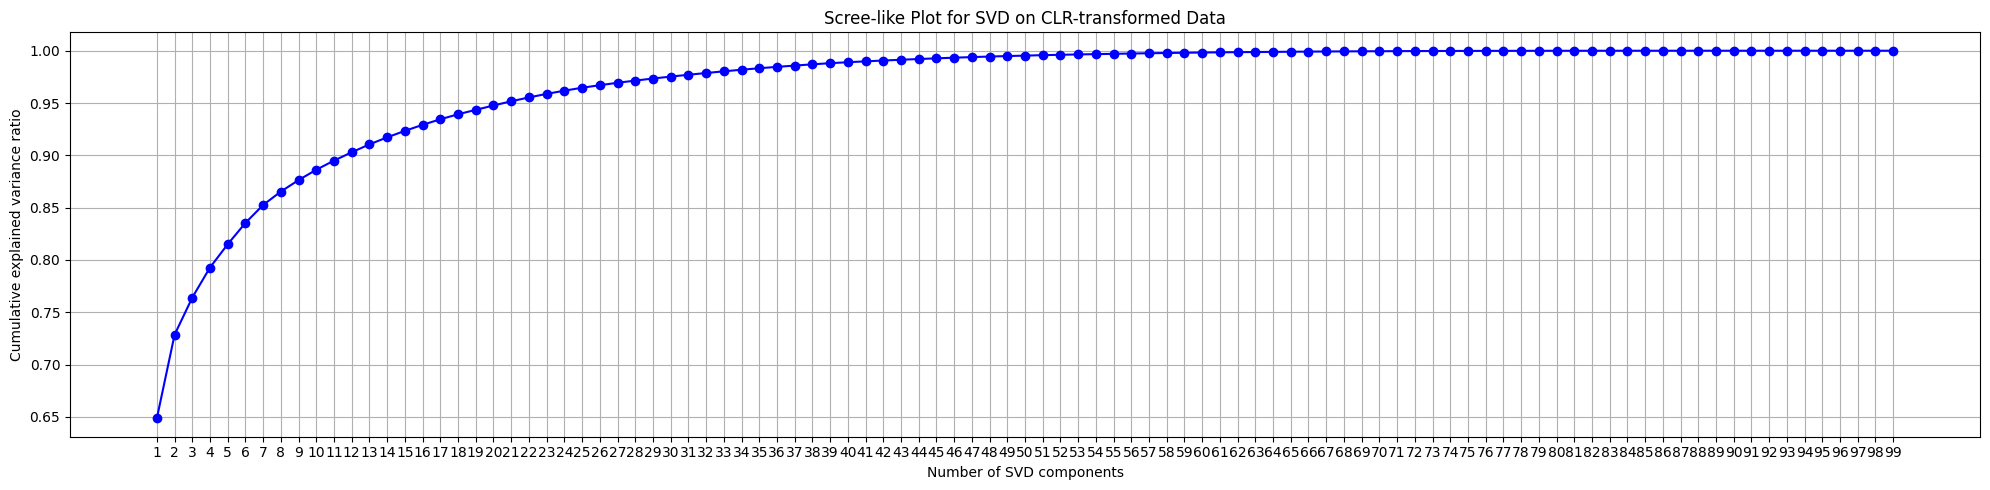

In [14]:

explained_variance = (s ** 2) / (len(df_train_val[predictors]) - 1)  # variance for each component
total_variance = explained_variance.sum()
explained_variance_ratio = explained_variance / total_variance
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

print("Explained variance ratio for each component:")
for i, ratio in enumerate(explained_variance_ratio):
    print(f"Component {i+1}: {ratio:.4f}")


plt.figure(figsize=(20, 5))
plt.plot(np.arange(1, len(s)+1), cumulative_variance_ratio, marker='o', color='blue')
plt.xlabel("Number of SVD components")
plt.ylabel("Cumulative explained variance ratio")
plt.title("Scree-like Plot for SVD on CLR-transformed Data")
plt.grid(True)
plt.xticks(np.arange(1, len(s)+1))
plt.tight_layout()
plt.show()

Note: on centered matrix PCA is seems quite similar to SVD (potential for discussion if the results are different)
https://stats.stackexchange.com/questions/134282/relationship-between-svd-and-pca-how-to-use-svd-to-perform-pca
https://math.stackexchange.com/questions/3869/what-is-the-intuitive-relationship-between-svd-and-pca

In [15]:
# Truncate matrices
k = 15 # Number of components to keep

U_k = U[:, :k]            # (n_samples x k)
s_k = s[:k]               # (k,)
VT_k = VT[:k, :]          # (k x n_features)
print(f"Shapes after truncation to {k} components:")
print(f"U_k: {U_k.shape}, s_k: {s_k.shape}, VT_k: {VT_k.shape}")

Shapes after truncation to 15 components:
U_k: (99, 15), s_k: (15,), VT_k: (15, 126)


In [16]:
X_train_val = U_k * s_k
X_test_val = np.dot(df_test[predictors], VT_k.T)
print(f"X_train_val shape: {X_train_val.shape}")
print(f"X_test_val shape: {X_test_val.shape}")

X_train_val shape: (99, 15)
X_test_val shape: (25, 15)


In [17]:
embeding_dim = k
reduced_train_X = X_train_val
reduced_test_X = X_test_val



After this point there should be: 
- reduced train set (reduced_train_X) 
- reduced test set (reduced_test_X) to be compatible with next parts of notebook. 

Both in the form of Numpy array or pandas df but without Y(label) -- only X(predictors)

- embeding_dim should be specified which is number of column in descibet sets. 

In [18]:
reduced_df_train = pd.DataFrame(reduced_train_X, columns=[f'{i+1}' for i in range(embeding_dim)])
components = reduced_df_train.columns.to_list()
reduced_df_train['pond_5'] = df_train_val['pond_5'].reset_index(drop=True)
reduced_df_train['pond_3'] = df_train_val['pond_3'].reset_index(drop=True)
reduced_df_train['pond_2'] = df_train_val['pond_2'].reset_index(drop=True)
reduced_df_test = pd.DataFrame(reduced_test_X, columns=[f'{i+1}' for i in range(embeding_dim)])
reduced_df_test['pond_5'] = df_test['pond_5'].reset_index(drop=True)
reduced_df_test['pond_3'] = df_test['pond_3'].reset_index(drop=True)
reduced_df_test['pond_2'] = df_test['pond_2'].reset_index(drop=True)


print(components)

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15']


In [19]:
reduced_df_train

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,pond_5,pond_3,pond_2
0,13.670352,1.904498,-2.476993,-0.559873,-3.697772,0.637471,-2.840201,2.161998,-3.159781,0.201981,-1.643572,1.442148,-1.216260,1.091018,-1.316776,1,1,0
1,10.013288,4.655732,-4.514957,1.531718,0.631093,-0.641025,-0.293586,-2.928590,1.279372,-0.440989,0.420211,0.445168,1.970765,0.149159,0.099548,0,0,0
2,16.181489,0.699532,0.079180,-2.779420,1.345862,2.595314,-0.062458,0.840900,-0.665109,-3.021656,-2.166691,-1.470835,2.256838,-1.816315,0.528988,0,0,0
3,13.670015,5.120255,0.958517,-0.938943,-2.226332,2.898622,-3.564490,-0.436490,-1.668174,2.097607,0.323531,-0.577646,2.045080,0.244472,1.131180,0,0,0
4,15.556349,-0.841102,-4.202708,-0.071892,-0.068324,1.155273,-1.706314,-0.487732,-0.371502,1.236803,-0.569208,1.463572,-4.017568,3.709396,-1.777881,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,16.228800,-2.679661,1.630987,-6.075573,6.353408,1.484635,4.693757,-1.468165,1.205928,2.417478,-2.096945,-1.087387,-0.334522,1.477850,-0.396854,4,2,1
95,15.730360,-2.477378,4.584961,-5.738267,-1.999608,-1.882787,-0.934311,0.154964,-3.672061,2.267132,0.558400,1.767178,2.255365,-0.626213,-0.808872,2,2,1
96,13.392560,5.484848,-0.436571,1.458149,3.084407,-2.413669,2.974524,3.107266,-0.459011,-2.509854,0.211437,-0.144948,1.344589,-0.418972,1.146166,1,1,0
97,10.711352,5.501210,-0.233781,5.902095,3.646226,-4.692588,0.757302,-0.735949,-2.627315,-0.199554,-0.666695,0.351434,-1.577415,-2.139711,0.872997,0,0,0


In [20]:
reduced_df_test

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,pond_5,pond_3,pond_2
0,12.688858,5.335057,-1.236802,0.000243,-3.282747,2.075340,1.322126,-0.154363,0.596399,-0.881503,-1.124831,-0.148725,0.317408,0.651003,-0.642678,3,1,0
1,12.932783,2.371469,4.396712,-3.773823,0.416309,1.035188,-3.297581,1.278473,1.671184,1.491827,2.321674,-0.665492,0.497211,-2.263117,-1.489625,0,0,0
2,15.694846,-4.651579,2.197511,-0.325697,-2.718363,-0.535148,3.577657,0.136536,-2.030984,1.256075,0.970754,2.225603,-0.676987,-0.287803,0.946324,2,2,1
3,10.193829,5.577863,-0.603946,0.778633,-4.006858,0.879924,-0.482001,-1.070400,1.778710,0.184147,-1.368293,-0.042342,1.114057,0.591326,-0.894554,1,1,0
4,9.958243,7.153364,0.332180,3.355596,-0.157499,-2.792646,0.045799,-0.831563,2.071405,0.873891,-0.291595,-0.283078,0.268330,0.653622,-0.591904,3,1,0
5,15.877196,0.116504,1.941372,0.504936,-0.776908,1.455343,2.305587,1.526075,-0.978898,0.310971,2.499667,-1.016643,0.433585,-0.839272,-1.169706,1,1,0
6,14.918102,2.129167,-0.234759,-2.359383,3.496899,3.537340,0.405150,0.237822,-0.005709,-1.611517,-1.802338,-0.277137,1.512496,0.134102,1.604459,0,0,0
7,10.946176,6.619804,-5.292998,0.582893,6.145971,-3.511772,1.967327,0.383706,2.826501,-0.341216,-2.337440,0.916764,2.086259,1.593290,2.328039,1,1,0
8,15.799617,-3.841895,-0.891584,3.047610,0.108081,2.876334,-0.316628,-1.357275,-0.471810,3.904575,1.040735,-0.117602,-3.988171,-0.696366,0.794445,2,2,1
9,12.688439,3.518537,-0.307976,1.749194,-1.114107,2.027872,-0.126587,-2.720213,-2.089052,1.227887,1.012866,-0.742802,-1.770821,-0.813526,0.720147,2,2,1


# 5 classes


In [56]:
target = 'pond_5'

## dense model 
fitting on embeded dataset


In [22]:
model5 = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.25),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(5, activation='softmax')

])
model5.summary()
model5.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │            45 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,869 (42.46 KB)

 Trainable params: 10,869 (42.46 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.5000 - loss: 1.9964
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
predicted classes:       [3 3 4 1 1 0 1 1 3 1 1 0 4 4 2 4 4 3 4 4]
true validation classes: [3 3 1 2 2 0 1 1 3 1 1 4 2 4 0 2 4 1 3 2]
mean confidence score: 118.583, sd confidence score: 244.2548
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5500 - loss: 1.8184
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
predicted classes:       [4 0 2 4 4 1 2 2 3 4 1 3 2 4 4 2 3 1 2 0]
true validation classes: [0 0 0 2 4 0 0 2 3 0 1 3 4 4 0 2 3 1 2 1]
mean confidence score: 3343.2337, sd confidence score: 13314.3757
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4500 - loss: 2.3543
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
predicted classes:       [1 1 1 2 1 1 4 3 1 4 1 3 4 4 2 3 3 1 1 3]
true validation classes: [1 1 2 2 0 4 0 3 0 4 3 1 4 2 2 1 3 1 4 1]
mean confidence score: 1430.8813, sd confidence scor

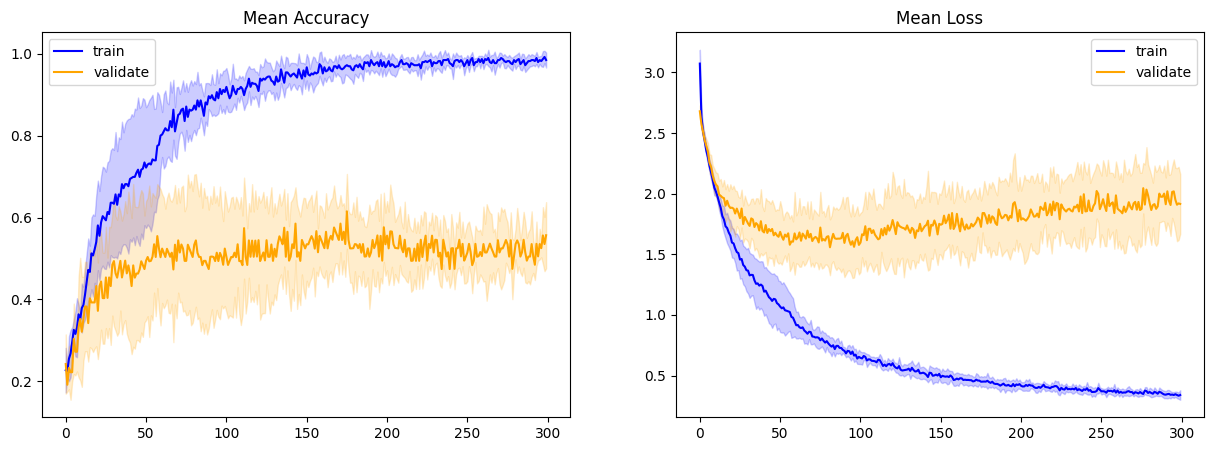

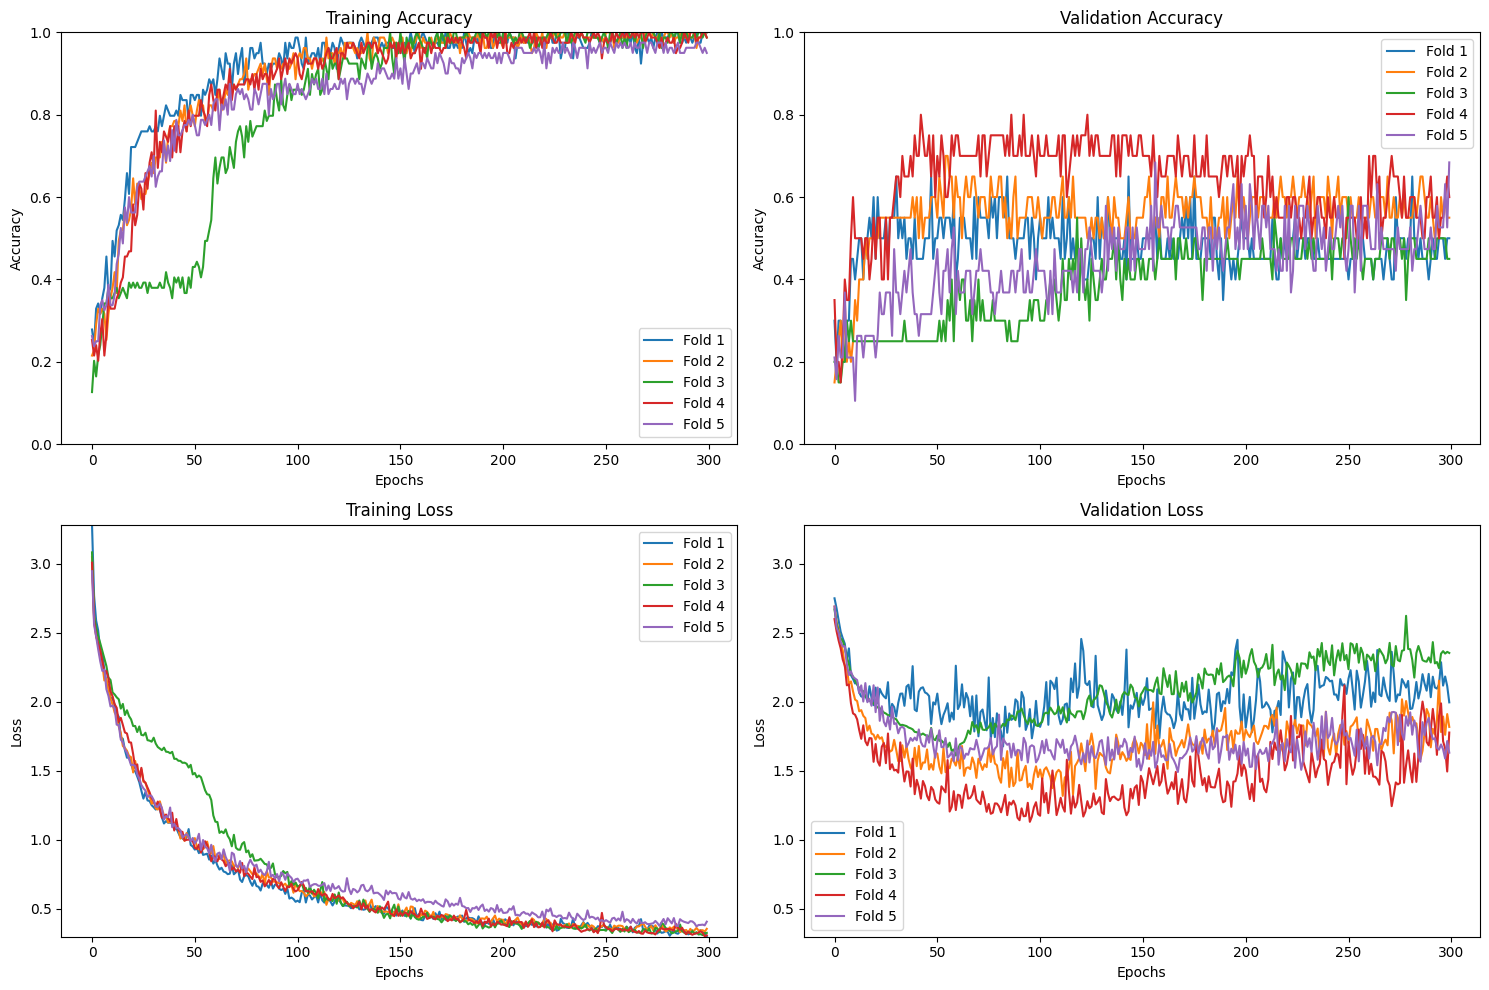

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
predicted classes:       [1 0 4 2 4 0 1 1 2 0 0 4 4 1 3 4 0 0 3]
true validation classes: [4 0 4 2 2 0 3 1 2 0 2 4 4 3 3 4 1 0 3]


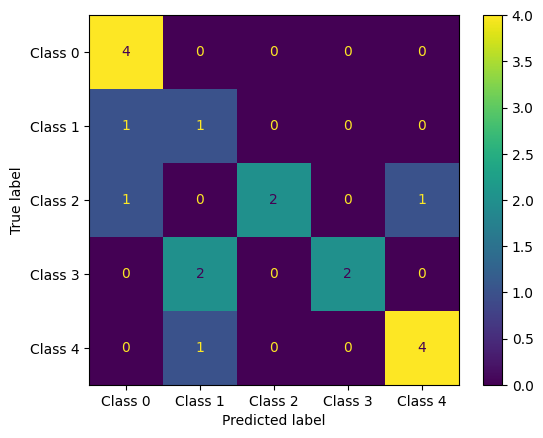

In [23]:
reset_weights(model5)
mean_acc_DNN_5_val, sd_acc_DNN_5_val = crossvalidate(reduced_df_train, model5, components, target, kf, 300)

### Test

In [57]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1882 - loss: 3.0908 - val_accuracy: 0.3200 - val_loss: 2.4962
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1150 - loss: 2.5251 - val_accuracy: 0.2000 - val_loss: 2.4141
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2905 - loss: 2.3498 - val_accuracy: 0.2400 - val_loss: 2.3201
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3613 - loss: 2.2158 - val_accuracy: 0.3200 - val_loss: 2.2465
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2849 - loss: 2.1118 - val_accuracy: 0.2800 - val_loss: 2.1203
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3615 - loss: 2.0060 - val_accuracy: 0.2800 - val_loss: 2.0385
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3047 - loss: 1.9691 - val_accuracy: 0.3600 - val_loss: 2.0034
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4040 - loss: 1.9163 - val_accuracy: 0.4000 - v

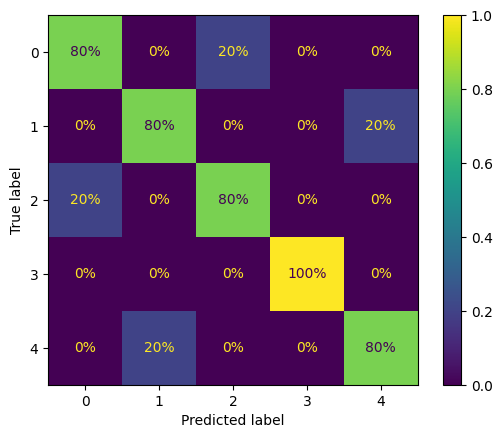

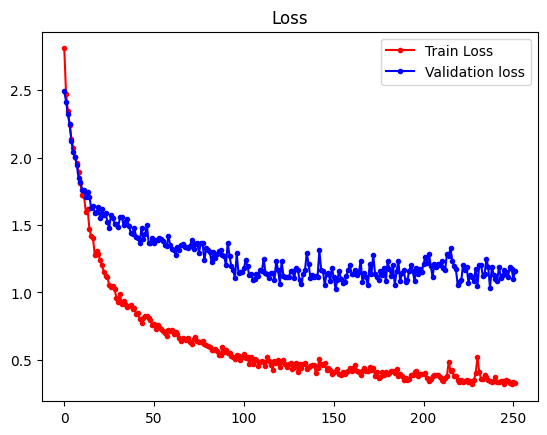

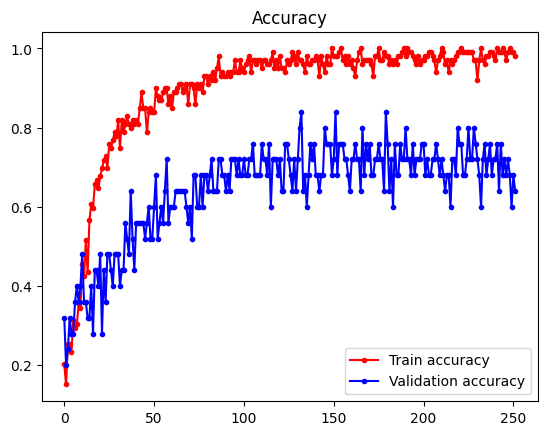

In [25]:
reset_weights(model5)
history5=model5.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, 
                    batch_size = 3, validation_data = (X_test, y_test), 
                    callbacks = [EarlyStopping(monitor='val_loss', patience=100, 
                                               restore_best_weights=True)])
acc_DNN_5_test = evaluate_model(model5, history5, X_test, y_test)

## Shallow model

In [58]:
model5_s = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(19, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(5, activation='softmax')
])
model5_s.summary()
model5_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 19)             │           304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 5)              │           100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 404 (1.58 KB)

 Trainable params: 404 (1.58 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.3500 - loss: 1.6925
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
predicted classes:       [3 3 4 2 4 2 0 2 3 1 0 0 4 4 2 3 4 3 4 4]
true validation classes: [3 3 1 2 2 0 1 1 3 1 1 4 2 4 0 2 4 1 3 2]
mean confidence score: 218.4938, sd confidence score: 778.6624
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5500 - loss: 1.5676
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
predicted classes:       [1 4 3 2 0 1 0 2 3 4 1 3 4 4 4 3 3 1 2 4]
true validation classes: [0 0 0 2 4 0 0 2 3 0 1 3 4 4 0 2 3 1 2 1]
mean confidence score: 7619.5424, sd confidence score: 32845.2344
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5500 - loss: 1.9973
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
predicted classes:       [1 3 3 2 0 1 4 3 1 4 1 3 4 0 2 3 3 1 4 1]
true validation classes: [1 1 2 2 0 4 0 3 0 4 3 1 4 2 2 1 3 1 4 1]
mean confidence score: 17946.0391, sd confidence sc

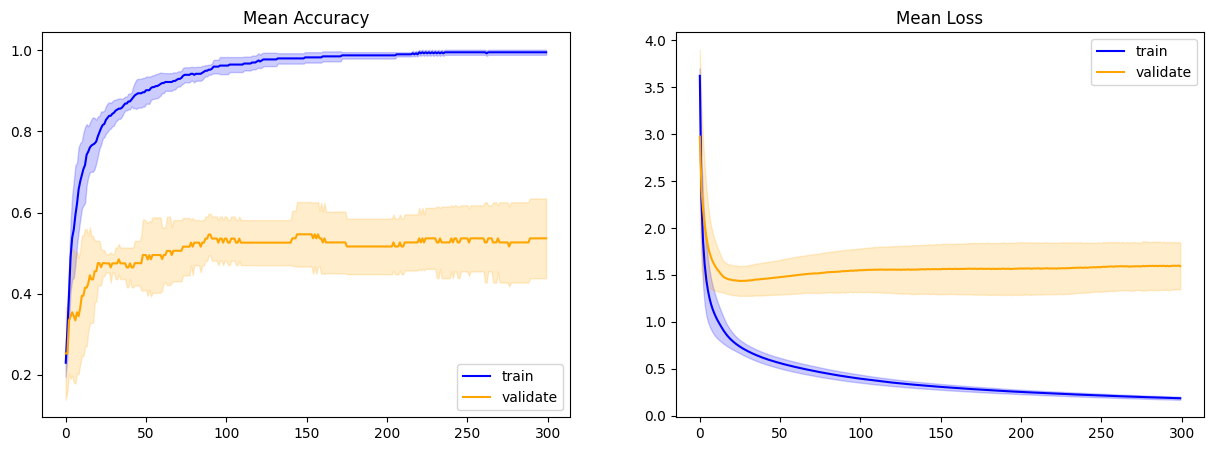

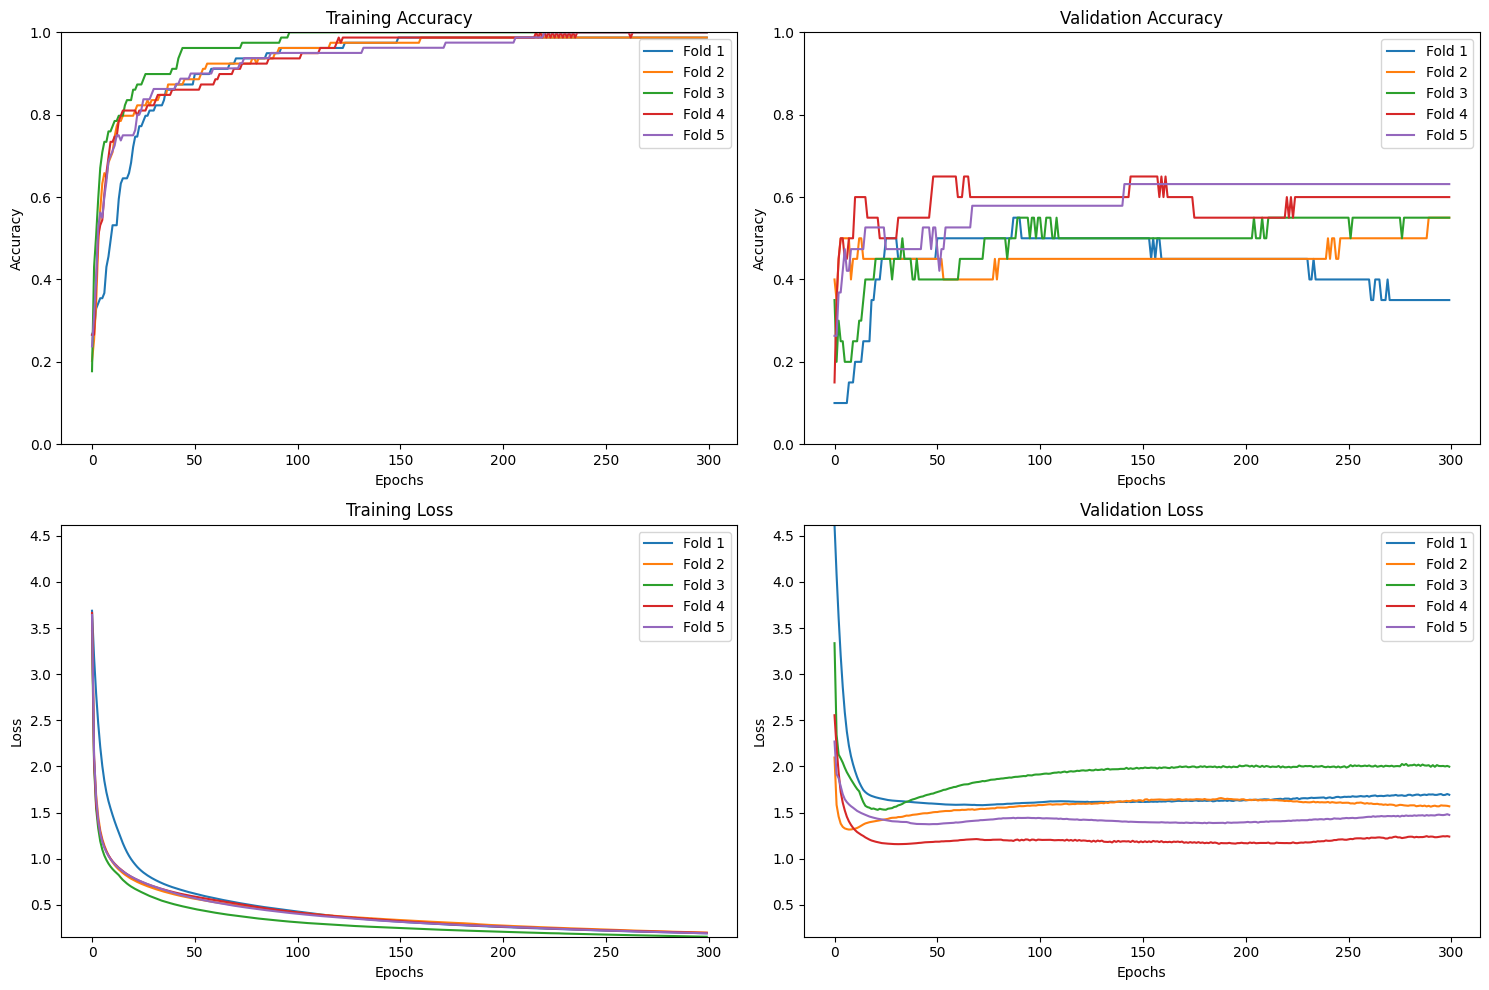

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
predicted classes:       [1 0 4 4 0 0 3 1 2 0 0 4 4 1 3 0 4 0 3]
true validation classes: [4 0 4 2 2 0 3 1 2 0 2 4 4 3 3 4 1 0 3]


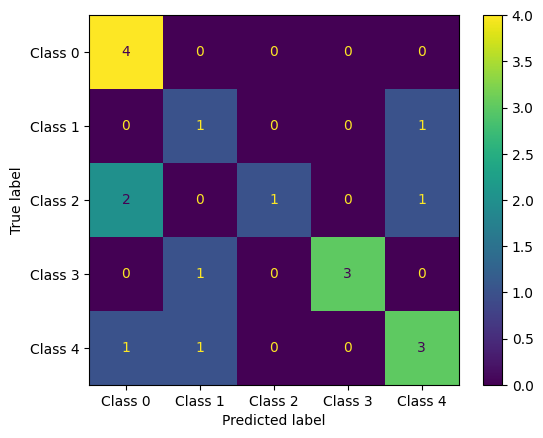

In [59]:
reset_weights(model5_s)
mean_acc_SNN_5_val, sd_acc_SNN_5_val = crossvalidate(reduced_df_train, model5_s, components, target,kf,300,True)

### Test    

In [60]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

In [61]:
model5_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

Epoch 1/500


33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9614 - loss: 0.2891 - val_accuracy: 0.5600 - val_loss: 1.1676
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9763 - loss: 0.2522 - val_accuracy: 0.5600 - val_loss: 1.1770
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9763 - loss: 0.2475 - val_accuracy: 0.5600 - val_loss: 1.1868
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9763 - loss: 0.2412 - val_accuracy: 0.5600 - val_loss: 1.1906
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9852 - loss: 0.2368 - val_accuracy: 0.5600 - val_loss: 1.1962
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9937 - loss: 0.2334 - val_accuracy: 0.5600 - val_loss: 1.1928
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9937 - loss: 0.2294 - val_accuracy: 0.5600 - val_loss: 1.1890
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9937 - loss: 0.2267 - val_accuracy: 0.5600 - val_loss: 1.1

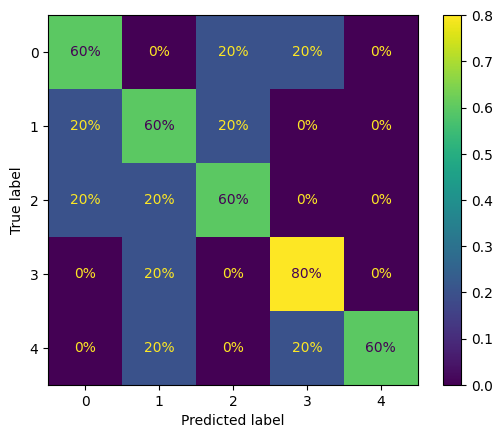

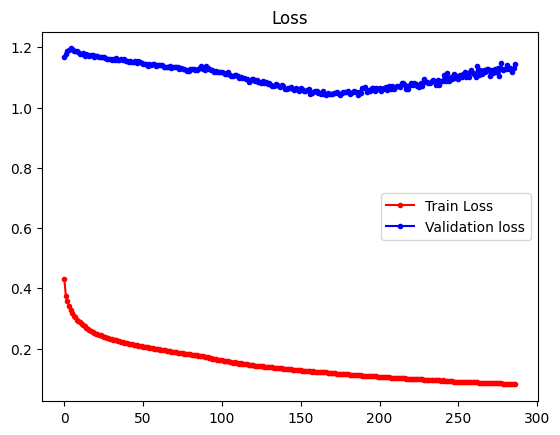

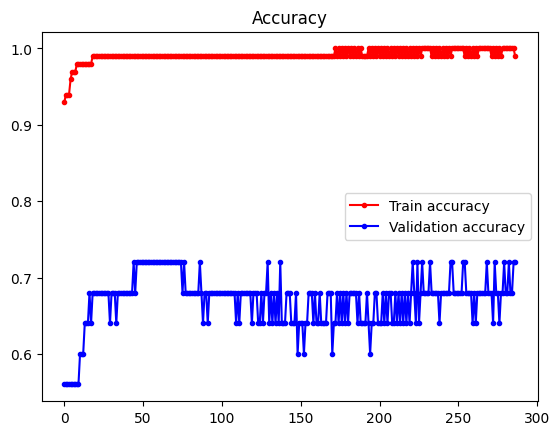

In [62]:
history5_s=model5_s.fit(X_train, y_train, epochs = 500, verbose = 1, 
                        shuffle = True, batch_size = 3, validation_data = (X_test, y_test), 
                        callbacks = [EarlyStopping(monitor='val_loss', patience=100, 
                                                   restore_best_weights=True)])
acc_SNN_5_test = evaluate_model(model5_s, history5_s, X_test, y_test)

## XGBoost

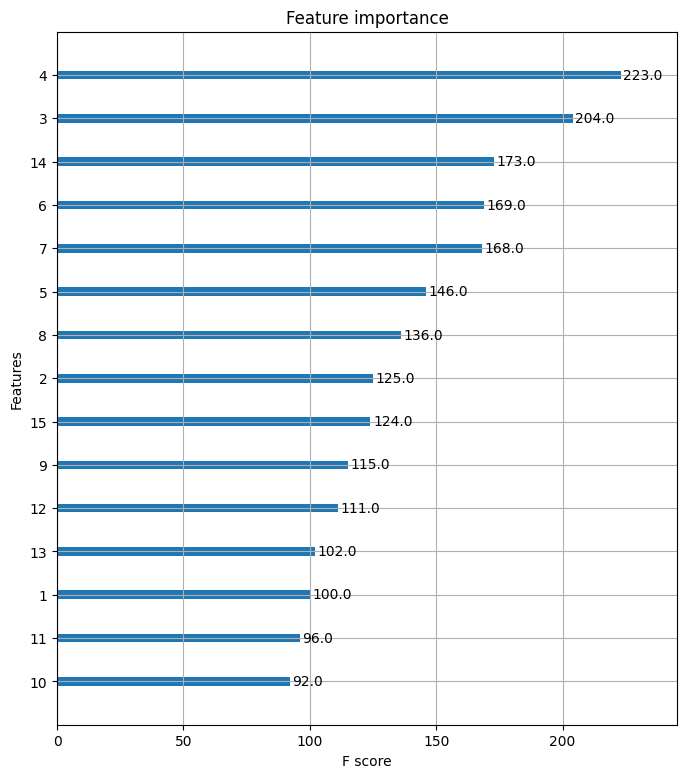

Accuracy0.44
true: [3 0 2 1 3 1 0 1 2 2 4 3 4 0 4 1 3 0 2 4 0 1 4 3 2]
predicted: [1. 2. 2. 1. 3. 4. 2. 1. 4. 4. 1. 4. 4. 3. 2. 1. 3. 4. 4. 4. 0. 1. 1. 3.
 1.]


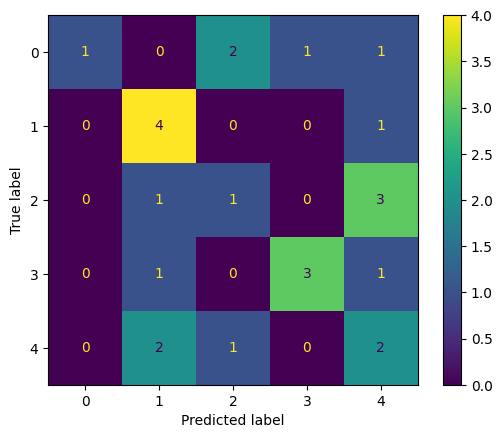

In [31]:
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=components)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=components)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_5_test = xgb_acc
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# 3 Classes

In [68]:
target = 'pond_3'

## Dense model

In [33]:
model3 = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.25),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(3, activation='softmax')
])


model3.summary()
model3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,851 (42.39 KB)

 Trainable params: 10,851 (42.39 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.7000 - loss: 1.2079
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
predicted classes:       [1 1 2 2 2 2 0 1 1 1 1 0 2 2 2 2 2 1 2 2]
true validation classes: [1 1 1 2 2 0 1 1 1 1 1 2 2 2 0 2 2 1 1 2]
mean confidence score: 1694.2213, sd confidence score: 5037.8106
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5500 - loss: 1.8509
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [1 2 1 2 2 1 2 2 1 1 2 1 2 2 2 2 1 1 2 2]
true validation classes: [0 0 0 2 2 0 0 2 1 0 1 1 2 2 0 2 1 1 2 1]
mean confidence score: 756.5804, sd confidence score: 1980.476
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7500 - loss: 1.2597
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [1 1 1 2 2 1 2 1 1 2 1 1 2 2 2 1 1 1 2 1]
true validation classes: [1 1 2 2 0 2 0 1 0 2 1 1 2 2 2 1 1 1 2 1]
mean confidence score: 15498.7294, sd confidence sco

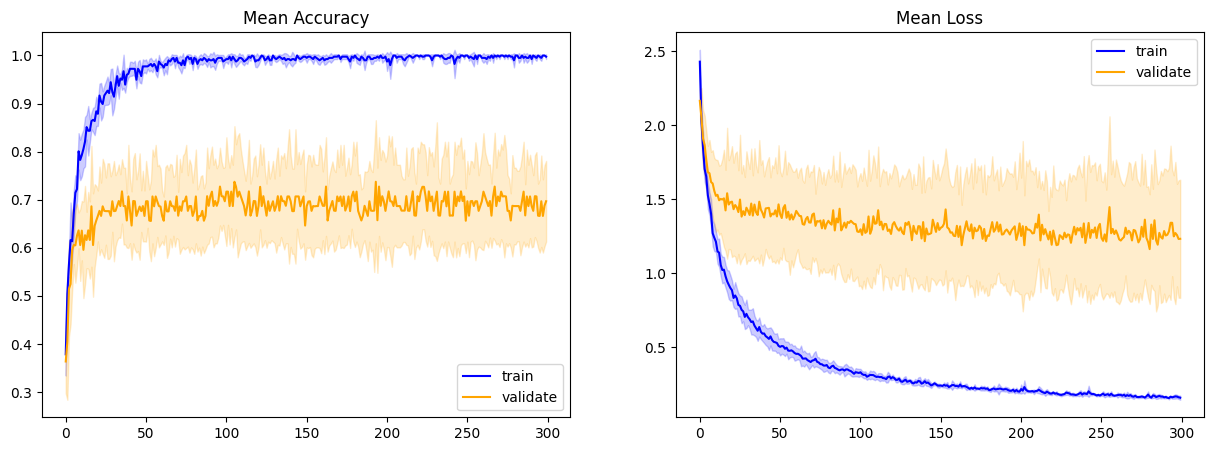

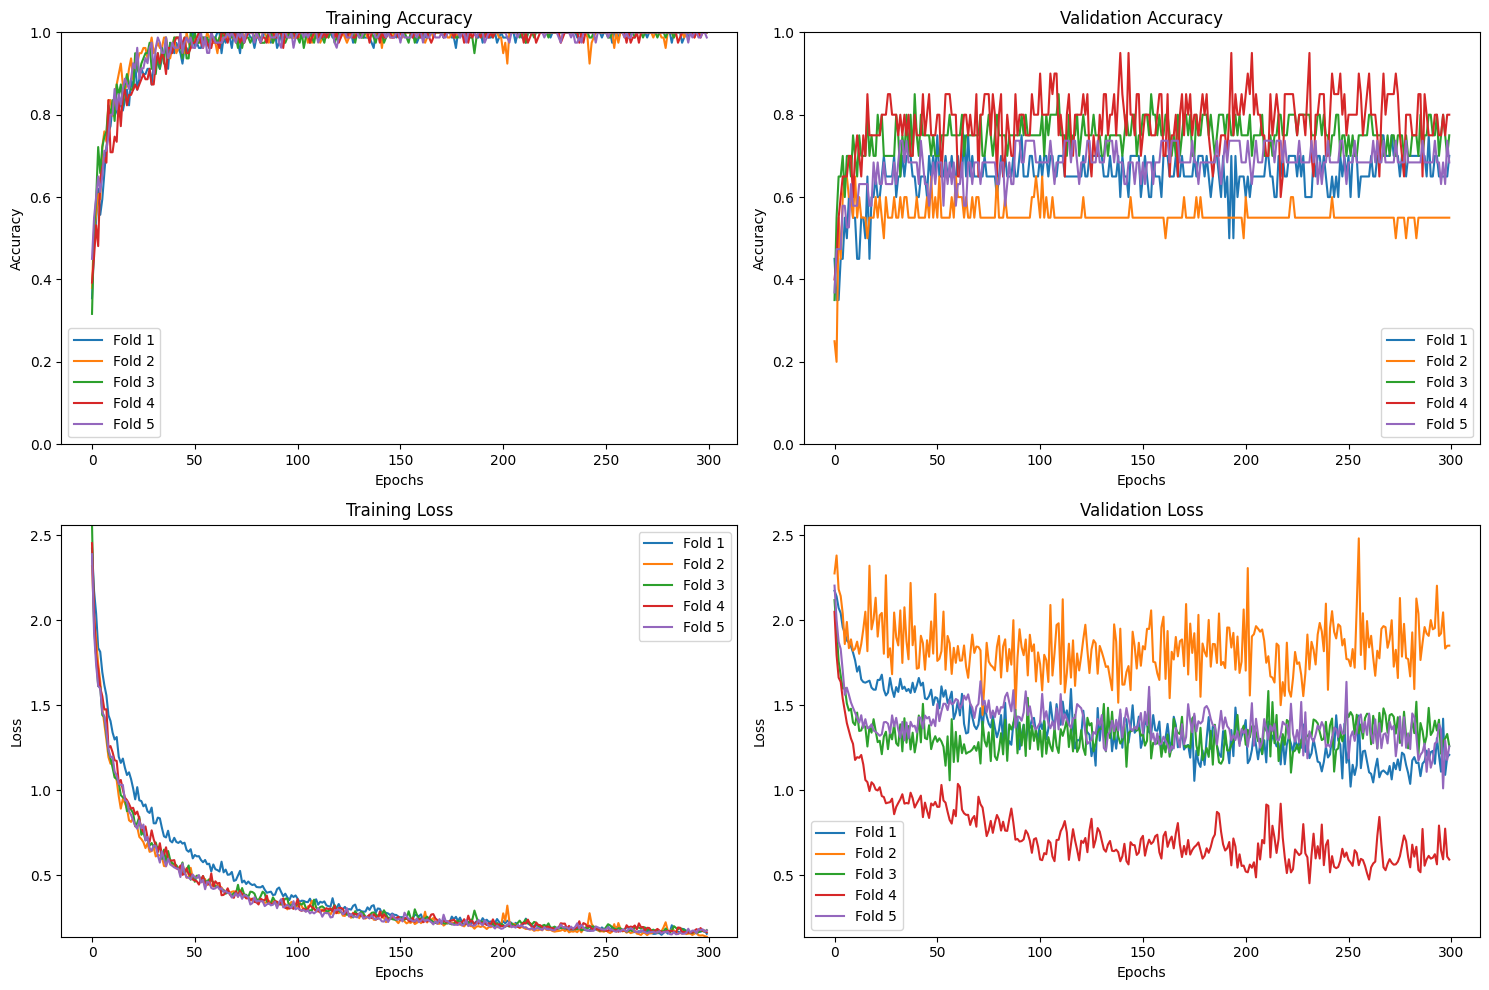

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
predicted classes:       [1 0 2 2 0 0 1 1 2 0 0 2 1 1 1 0 2 0 1]
true validation classes: [2 0 2 2 2 0 1 1 2 0 2 2 2 1 1 2 1 0 1]


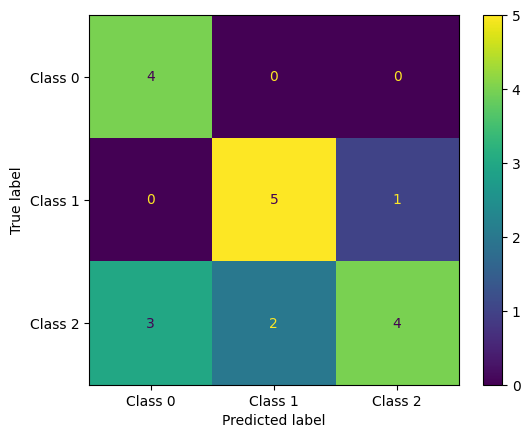

In [34]:
reset_weights(model3)
mean_acc_DNN_3_val, sd_acc_DNN_3_val = crossvalidate(reduced_df_train, model3, components, 'pond_3' ,kf,300)

### Test

In [69]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

Epoch 1/500


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3121 - loss: 2.4866 - val_accuracy: 0.3200 - val_loss: 2.0103
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3622 - loss: 1.9560 - val_accuracy: 0.4800 - val_loss: 1.8201
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4086 - loss: 1.8701 - val_accuracy: 0.6400 - val_loss: 1.7066
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4992 - loss: 1.6870 - val_accuracy: 0.4400 - val_loss: 1.5146
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5459 - loss: 1.5323 - val_accuracy: 0.7200 - val_loss: 1.3299
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5194 - loss: 1.4463 - val_accuracy: 0.6000 - val_loss: 1.2626
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5785 - loss: 1.3620 - val_accuracy: 0.6800 - val_loss: 1.2052
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5934 - loss: 1.2886 - val_accuracy: 0.6000 - val_loss: 1.3

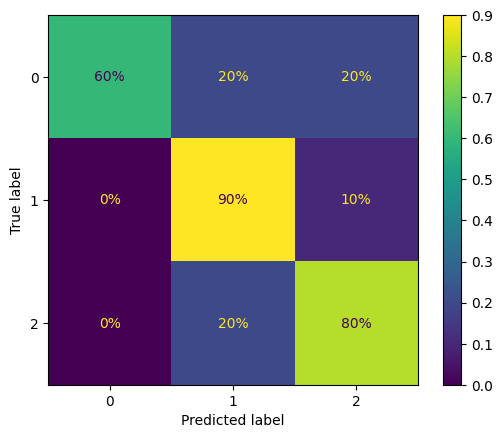

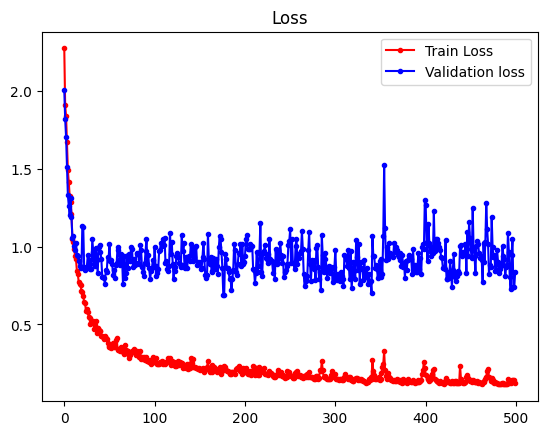

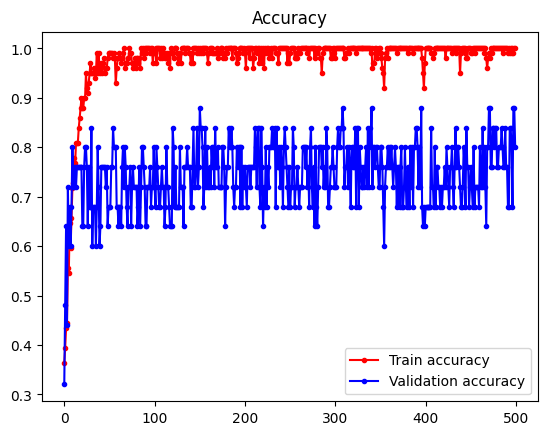

In [36]:
reset_weights(model3)
history3 = model3.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test))
acc_DNN_3_test = evaluate_model(model3, history3, X_test, y_test)

## Shallow model 

In [64]:
model3_s = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(19, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(3, activation='softmax')
])
model3_s.summary()
model3_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 19)             │           304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 3)              │            60 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 364 (1.42 KB)

 Trainable params: 364 (1.42 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.6000 - loss: 1.6428
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
predicted classes:       [1 1 2 2 2 2 0 2 1 1 1 0 2 2 2 2 1 1 2 2]
true validation classes: [1 1 1 2 2 0 1 1 1 1 1 2 2 2 0 2 2 1 1 2]
mean confidence score: 333.2035, sd confidence score: 518.9558
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5500 - loss: 1.9243
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
predicted classes:       [1 2 2 2 2 1 2 2 1 2 1 1 2 2 2 1 1 1 2 0]
true validation classes: [0 0 0 2 2 0 0 2 1 0 1 1 2 2 0 2 1 1 2 1]
mean confidence score: 6250.9104, sd confidence score: 24512.9617
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.6500 - loss: 0.9625
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
predicted classes:       [1 2 1 2 0 1 2 1 1 2 1 1 2 0 2 1 1 1 1 1]
true validation classes: [1 1 2 2 0 2 0 1 0 2 1 1 2 2 2 1 1 1 2 1]
mean confidence score: 4769.4494, sd confidence sco

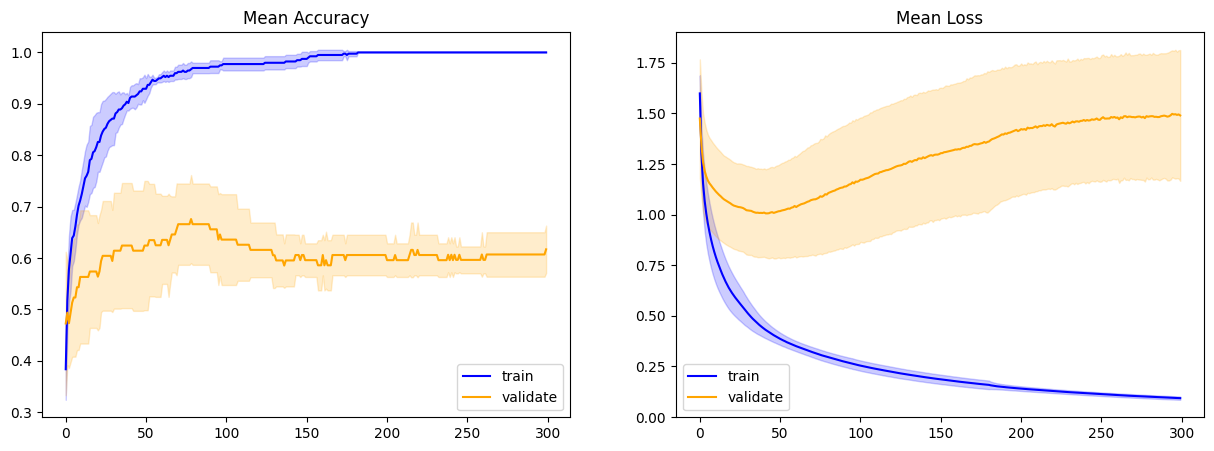

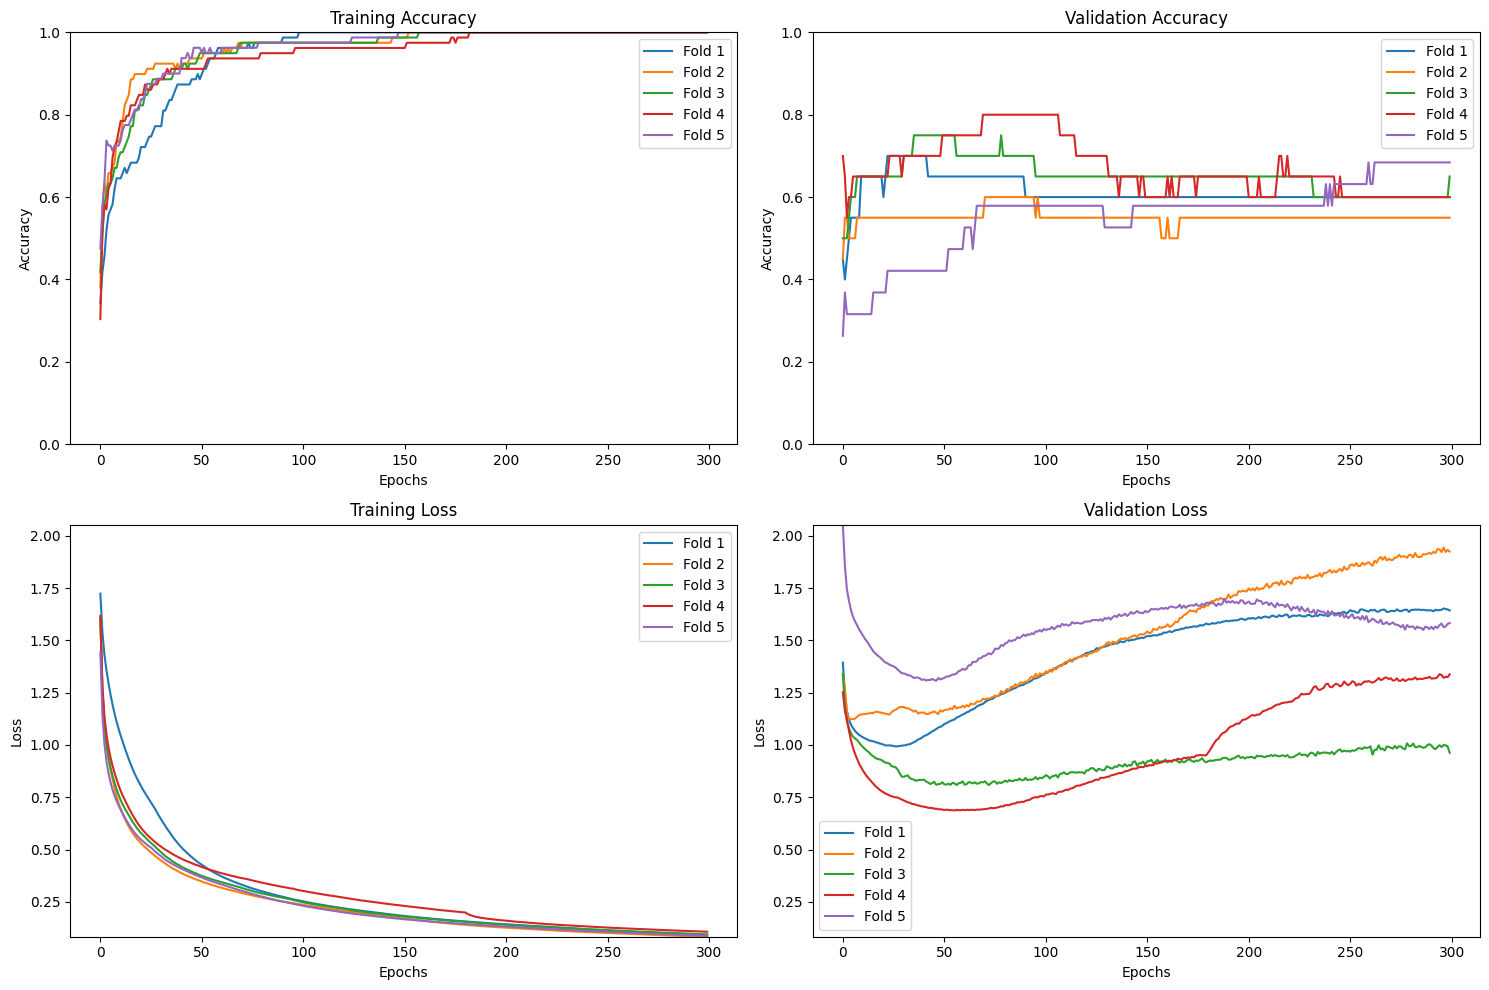

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
predicted classes:       [1 0 2 2 0 0 1 1 2 0 0 2 2 1 1 0 2 0 2]
true validation classes: [2 0 2 2 2 0 1 1 2 0 2 2 2 1 1 2 1 0 1]


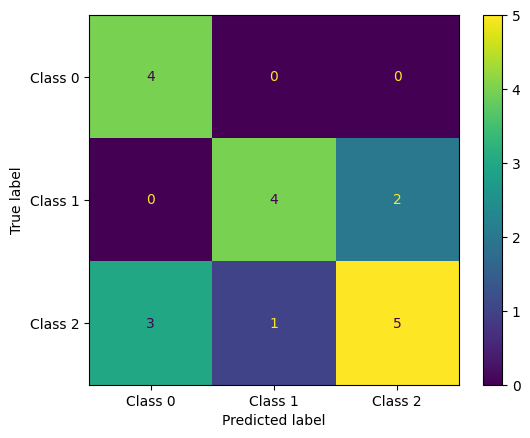

In [65]:
reset_weights(model3)
mean_acc_SNN_3_val, sd_acc_SNN_3_val = crossvalidate(reduced_df_train, model3_s, components, 'pond_3' ,kf,300)

### test

In [71]:
model3_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6400 - loss: 1.0438
[1.0437740087509155, 0.6399999856948853]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
Predicted values: [1 2 2 1 1 2 2 1 1 2 1 2 2 0 2 0 1 0 1 2 0 1 1 1 2]
True values: [1 0 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 0 1 2 1 2]
Test accuracy: 0.6000000238418579


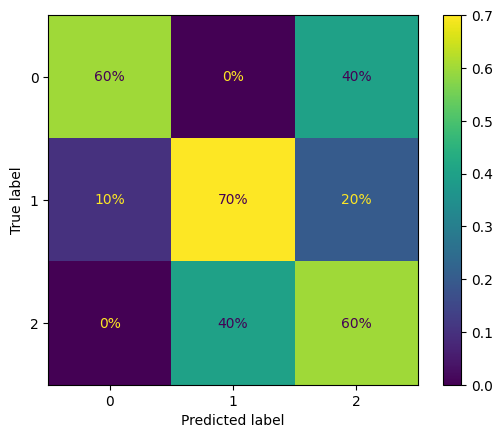

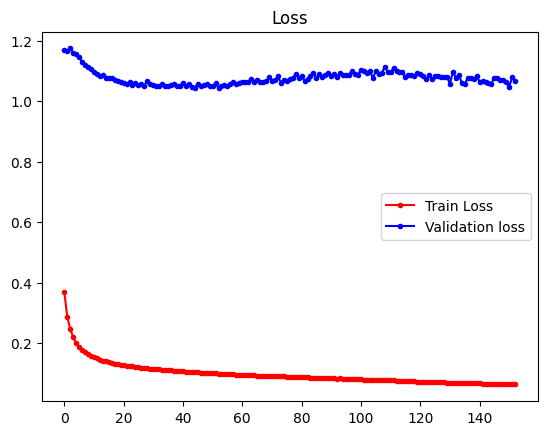

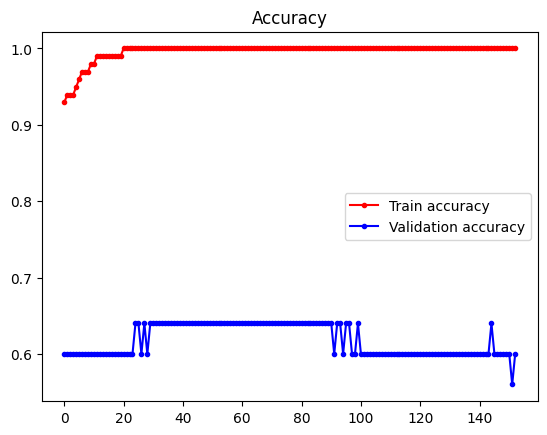

In [72]:
history3_s=model3_s.fit(X_train, y_train, epochs = 500, verbose = 0, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_SNN_3_test = evaluate_model(model3_s, history3_s, X_test, y_test)

## XGBoost

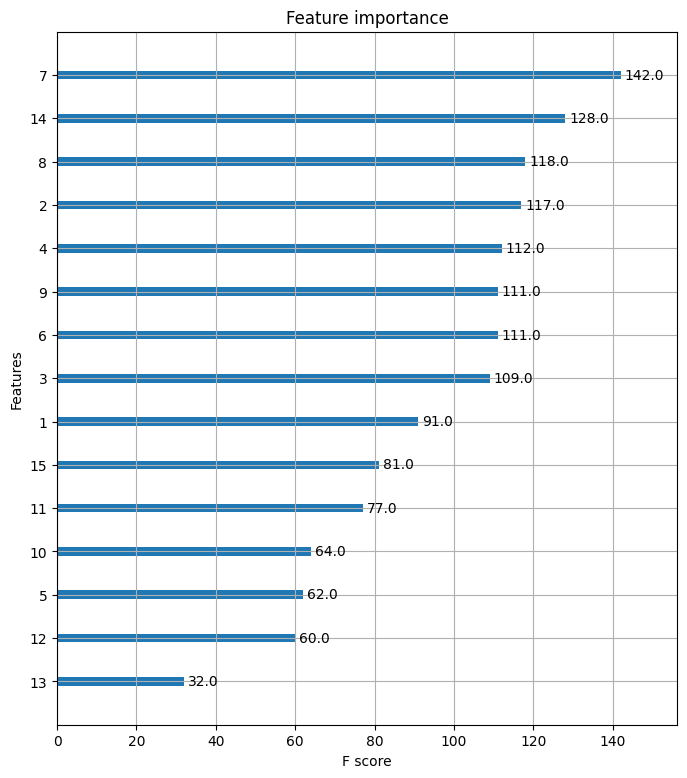

Accuracy0.68
true: [1 0 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 0 1 2 1 2]
predicted: [1. 2. 2. 1. 1. 2. 2. 1. 2. 2. 2. 2. 2. 1. 2. 1. 1. 0. 2. 2. 1. 1. 1. 1.
 1.]


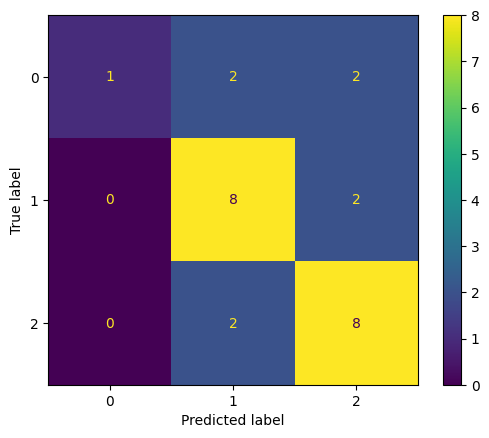

In [41]:
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=components)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=components)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_3_test = xgb_acc 
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# 2 Classes

In [73]:
target = 'pond_2'

## Dense model

In [74]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

In [44]:
model2 = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.25),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(2, activation='softmax')
])
model2.summary()
model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,842 (42.35 KB)

 Trainable params: 10,842 (42.35 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.7500 - loss: 0.8599
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
predicted classes:       [0 0 1 1 1 1 0 0 0 0 0 0 1 1 1 1 1 0 1 1]
true validation classes: [0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0 1]
mean confidence score: 70404.7771, sd confidence score: 288182.7773
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8000 - loss: 0.6682
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [0 0 0 0 1 0 1 1 0 0 0 0 1 1 1 0 0 0 1 0]
true validation classes: [0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0]
mean confidence score: 835.6937, sd confidence score: 1595.7358
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7500 - loss: 0.9249
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
predicted classes:       [0 0 0 1 1 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0]
true validation classes: [0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 1 0]
mean confidence score: 1026.4064, sd confidence 

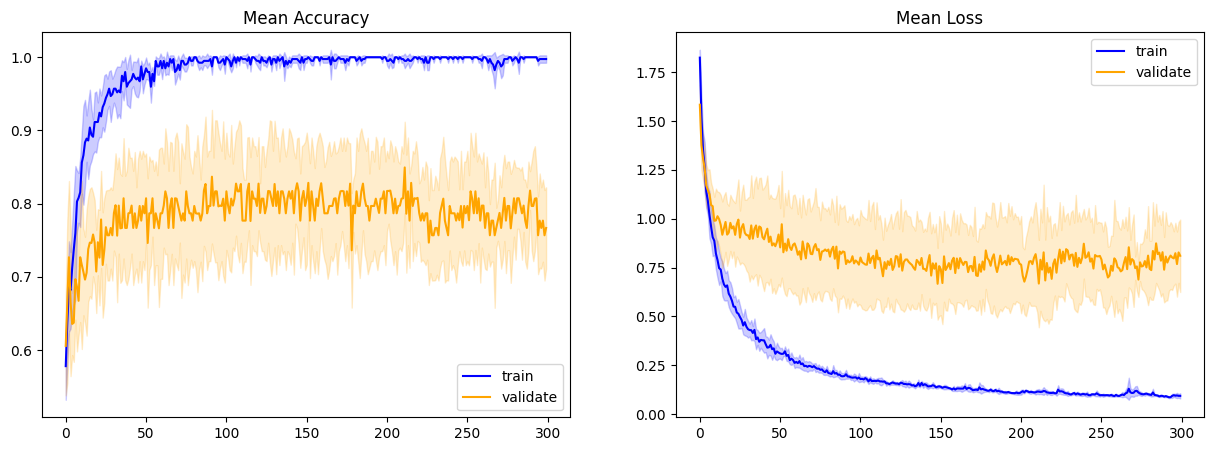

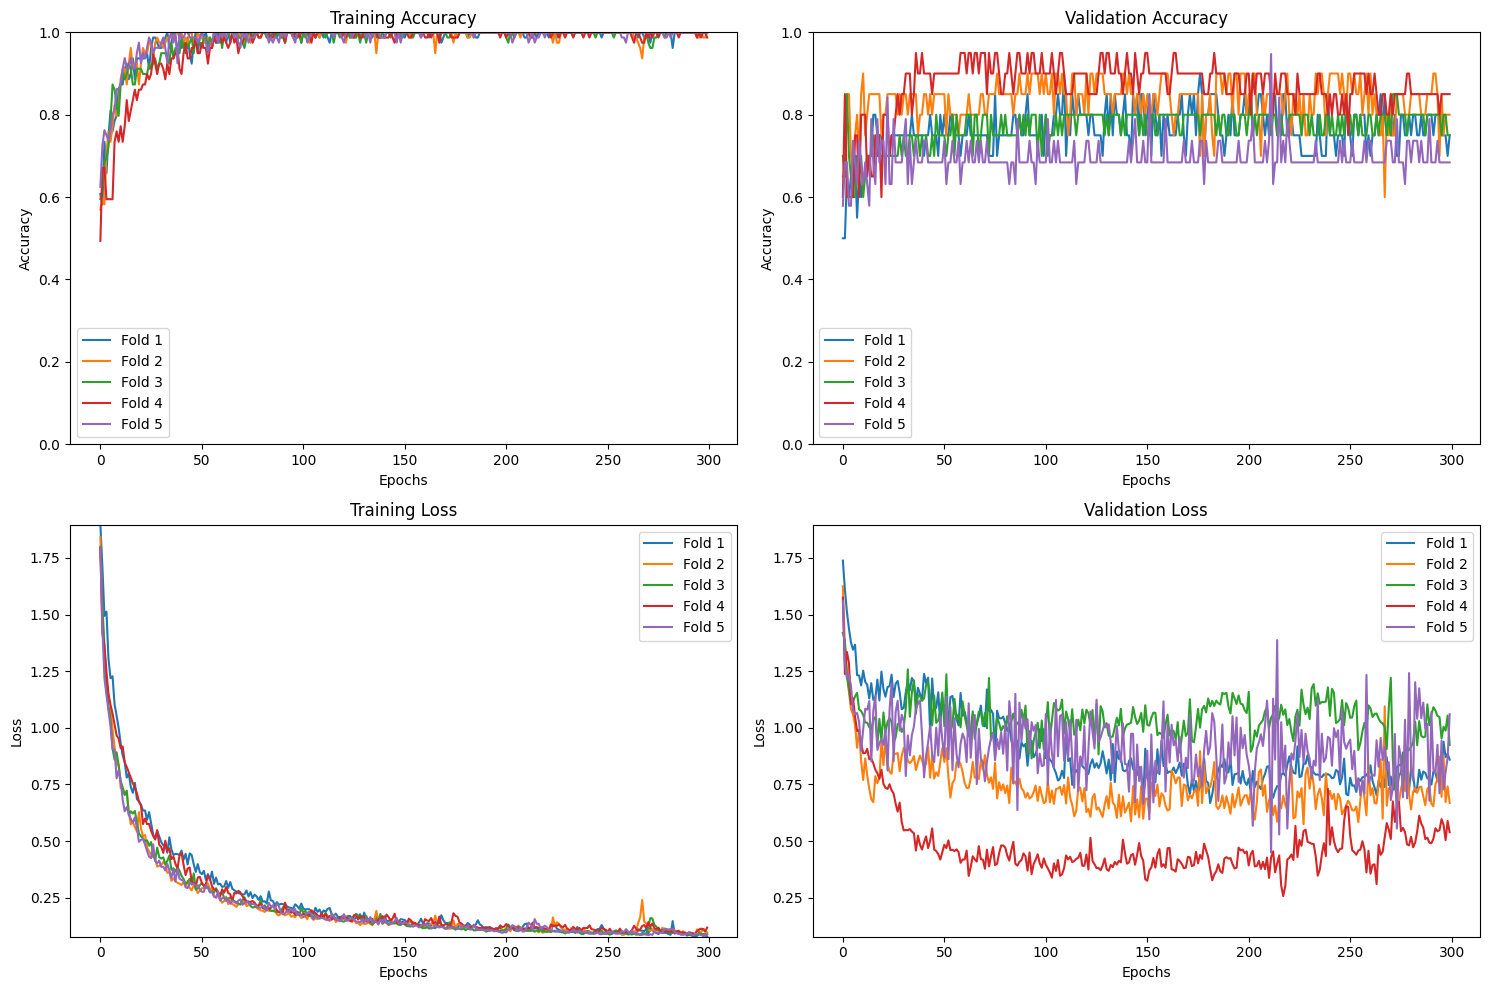

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [0 0 1 1 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0]
true validation classes: [1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0]


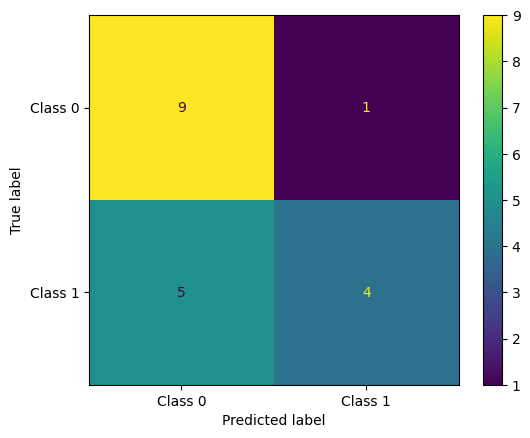

In [45]:
#reset_weights(model4)
mean_acc_DNN_2_val, sd_acc_DNN_2_val = crossvalidate(reduced_df_train, model2, components, target ,kf,300)

### Test

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9271 - loss: 0.2949 - val_accuracy: 0.7200 - val_loss: 0.8090
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9827 - loss: 0.2138 - val_accuracy: 0.7600 - val_loss: 0.8597
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9457 - loss: 0.2142 - val_accuracy: 0.7600 - val_loss: 1.0256
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9854 - loss: 0.1447 - val_accuracy: 0.7600 - val_loss: 1.0918
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9777 - loss: 0.1835 - val_accuracy: 0.7200 - val_loss: 1.0119
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9680 - loss: 0.1751 - val_accuracy: 0.7600 - val_loss: 0.7877
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9802 - loss: 0.1866 - val_accuracy: 0.7200 - val_loss: 1.0600
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9836 - loss: 0.1552 - val_accuracy: 0.7200 - v

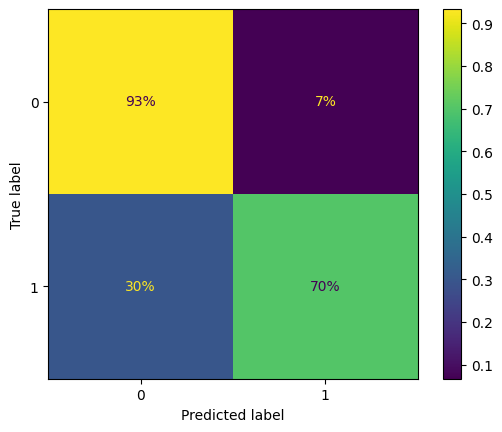

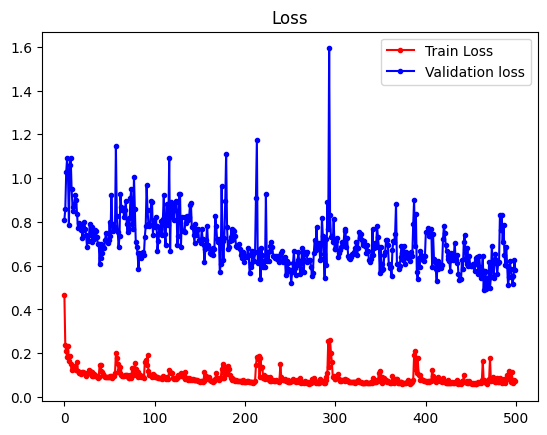

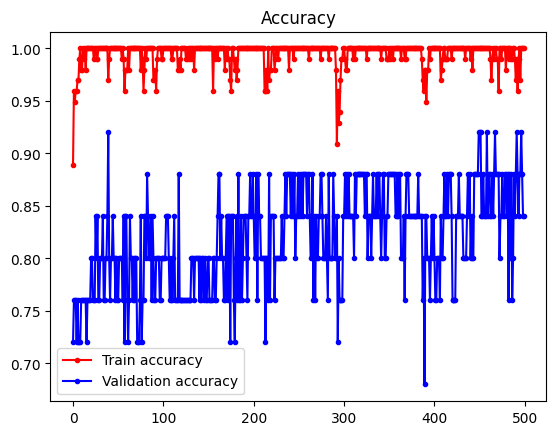

In [46]:
#  reset_weights(model4)
history2 = model2.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test))
acc_DNN_2_test = evaluate_model(model2, history2, X_test, y_test)

## Shallow model

In [75]:
model2_s = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(19, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(2, activation='softmax')
])
model2_s.summary()
model2_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                │ (None, 19)             │           304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 2)              │            40 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344 (1.34 KB)

 Trainable params: 344 (1.34 KB)

 Non-trainable params: 0 (0.00 B)

Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.7500 - loss: 1.1837
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
predicted classes:       [0 0 1 1 1 1 0 0 0 0 0 0 1 1 1 1 1 0 1 1]
true validation classes: [0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0 1]
mean confidence score: 11824.3361, sd confidence score: 31745.2219
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8000 - loss: 1.4070
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [0 0 0 1 1 0 1 1 0 0 0 0 0 1 1 0 0 0 1 0]
true validation classes: [0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0]
mean confidence score: 57199811.965, sd confidence score: 247986918.5851
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6500 - loss: 0.8314
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
predicted classes:       [0 0 0 1 0 0 1 0 0 0 0 0 1 0 1 0 1 0 0 0]
true validation classes: [0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 1 0]
mean confidence score: 815326596.5434, s

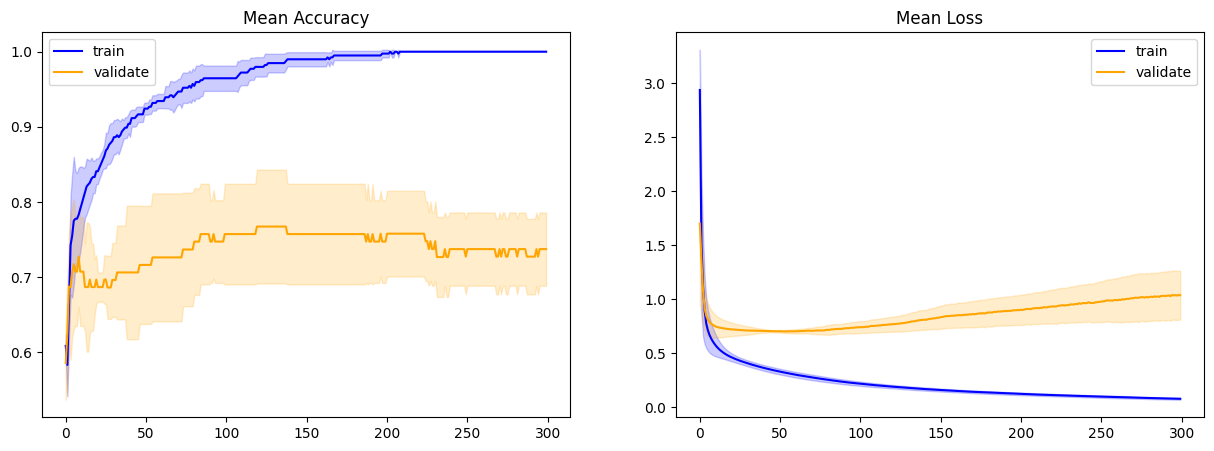

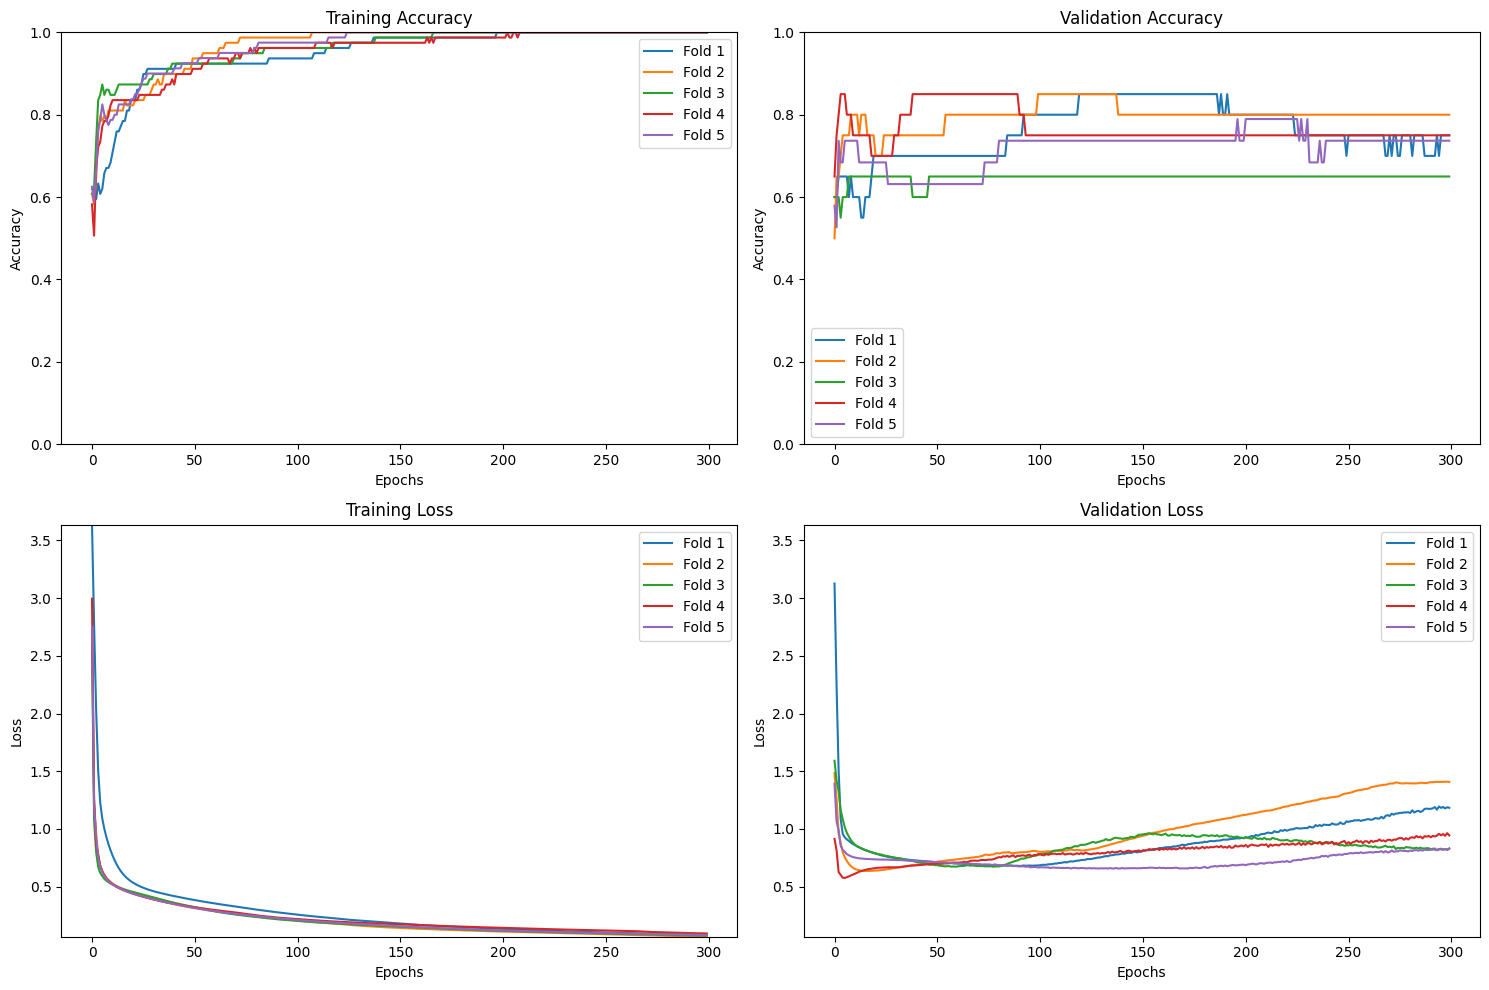

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [0 0 1 1 0 0 0 0 0 0 1 1 1 0 0 0 1 0 0]
true validation classes: [1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0]


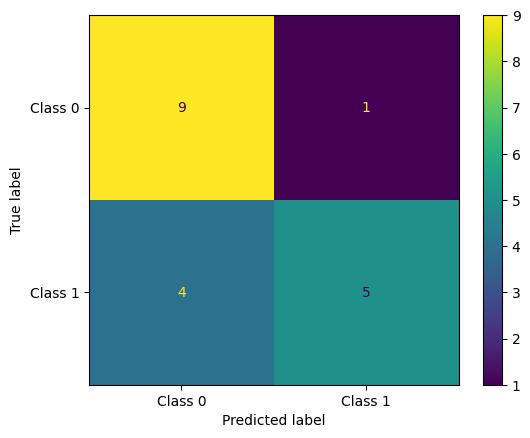

In [76]:
mean_acc_SNN_2_val, sd_acc_SNN_2_val = crossvalidate(reduced_df_train, model2_s, components, target ,kf,300,True)

### test

In [77]:
model2_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])   

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7600 - loss: 0.8136
[0.8135740756988525, 0.7599999904632568]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Predicted values: [0 1 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1]
True values: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
Test accuracy: 0.7599999904632568


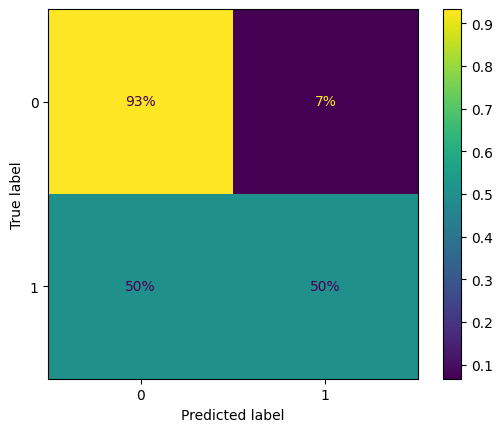

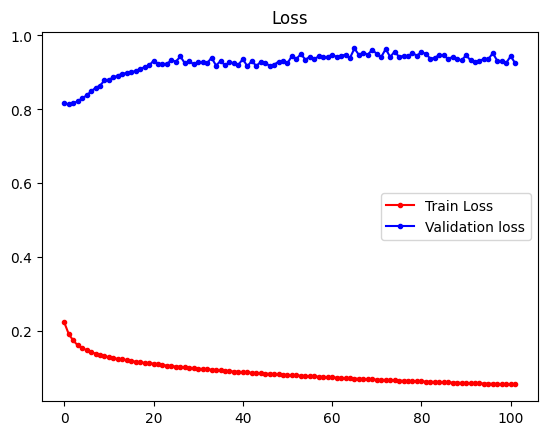

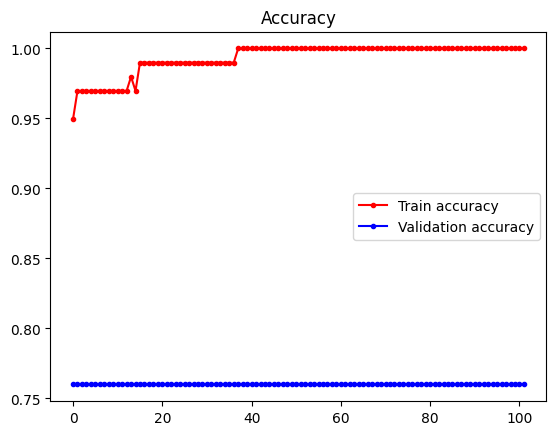

In [78]:
history2_s=model2_s.fit(X_train, y_train, epochs = 500, verbose = 0, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_SNN_2_test = evaluate_model(model2_s, history2_s, X_test, y_test)

## XGboost

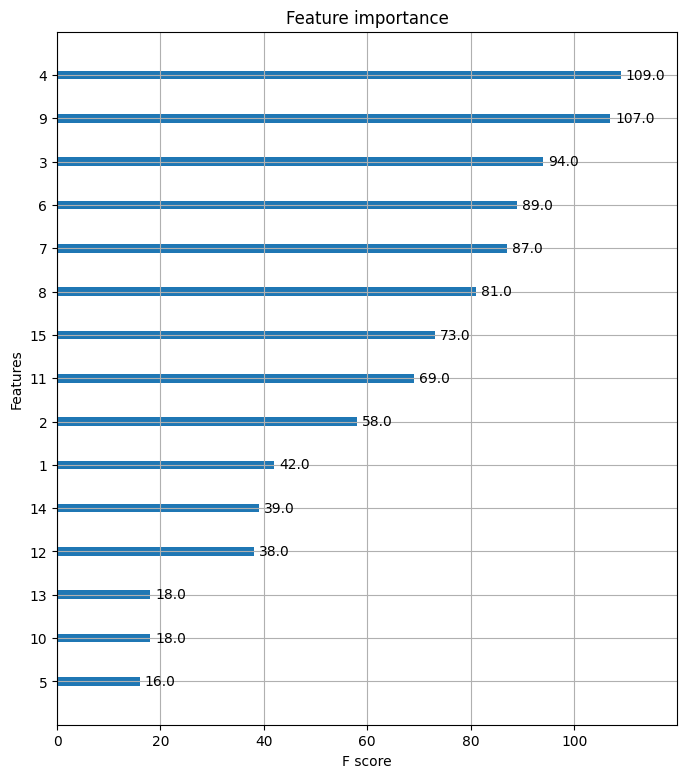

Accuracy0.84
true: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
predicted: [0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 1. 1. 0. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0.
 1.]


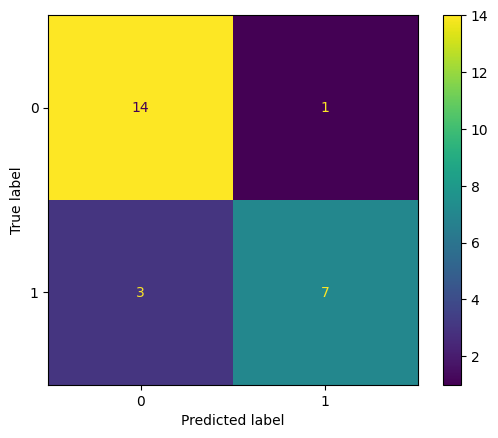

In [51]:
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=components)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=components)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_2_test = xgb_acc
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# END


In [79]:
print("DNN")
print(f"Accuracy class 5: {round(mean_acc_DNN_5_val,2)}, sd: {round(sd_acc_DNN_5_val,2)}, test: {acc_DNN_5_test}")
print(f"Accuracy class 3: {round(mean_acc_DNN_3_val,2)}, sd: {round(sd_acc_DNN_3_val,2)}, test: {acc_DNN_3_test}")
print(f"Accuracy class 2: {round(mean_acc_DNN_2_val,2)}, sd: {round(sd_acc_DNN_2_val,2)}, test: {acc_DNN_2_test}")
print("SNN")
print(f"Accuracy class 5: {round(mean_acc_SNN_5_val,2)}, sd: {round(sd_acc_SNN_5_val,2)}, test: {acc_SNN_5_test}")
print(f"Accuracy class 3: {round(mean_acc_SNN_3_val,2)}, sd: {round(sd_acc_SNN_3_val,2)}, test: {acc_SNN_3_test}")
print(f"Accuracy class 2: {round(mean_acc_SNN_2_val,2)}, sd: {round(sd_acc_SNN_2_val,2)}, test: {acc_SNN_2_test}")
print("XGB")
print(f"Accuracy class 5: {acc_XGB_5_test}")
print(f"Accuracy class 3: {acc_XGB_3_test}")
print(f"Accuracy class 2: {acc_XGB_2_test}")


DNN
Accuracy class 5: 0.56, sd: 0.08, test: 0.6399999856948853
Accuracy class 3: 0.7, sd: 0.08, test: 0.800000011920929
Accuracy class 2: 0.77, sd: 0.06, test: 0.8399999737739563
SNN
Accuracy class 5: 0.54, sd: 0.1, test: 0.7200000286102295
Accuracy class 3: 0.62, sd: 0.05, test: 0.6000000238418579
Accuracy class 2: 0.74, sd: 0.05, test: 0.7599999904632568
XGB
Accuracy class 5: 0.44
Accuracy class 3: 0.68
Accuracy class 2: 0.84


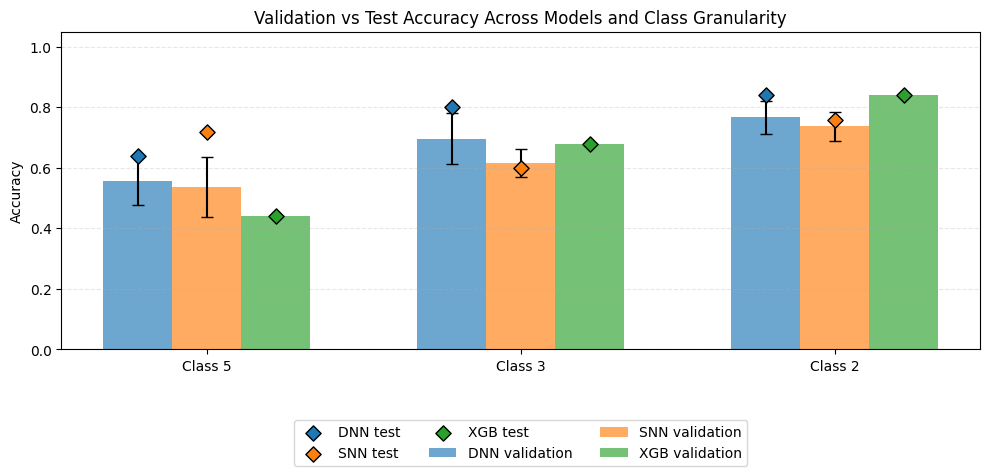

In [80]:
accuracy_rows = [
    ("DNN", "Class 5", mean_acc_DNN_5_val, sd_acc_DNN_5_val, acc_DNN_5_test),
    ("DNN", "Class 3", mean_acc_DNN_3_val, sd_acc_DNN_3_val, acc_DNN_3_test),
    ("DNN", "Class 2", mean_acc_DNN_2_val, sd_acc_DNN_2_val, acc_DNN_2_test),
    ("SNN", "Class 5", mean_acc_SNN_5_val, sd_acc_SNN_5_val, acc_SNN_5_test),
    ("SNN", "Class 3", mean_acc_SNN_3_val, sd_acc_SNN_3_val, acc_SNN_3_test),
    ("SNN", "Class 2", mean_acc_SNN_2_val, sd_acc_SNN_2_val, acc_SNN_2_test),
    ("XGB", "Class 5", acc_XGB_5_test, 0.0, acc_XGB_5_test),
    ("XGB", "Class 3", acc_XGB_3_test, 0.0, acc_XGB_3_test),
    ("XGB", "Class 2", acc_XGB_2_test, 0.0, acc_XGB_2_test),
]

accuracy_df = pd.DataFrame(
    accuracy_rows,
    columns=["Model", "Class", "val_mean", "val_sd", "test_acc"],
)

class_labels = ["Class 5", "Class 3", "Class 2"]
model_order = ["DNN", "SNN", "XGB"]
x_positions = np.arange(len(class_labels))
bar_width = 0.22
palette = {"DNN": "#1f77b4", "SNN": "#ff7f0e", "XGB": "#2ca02c"}

fig, ax = plt.subplots(figsize=(10, 5))
for idx, model in enumerate(model_order):
    subset = accuracy_df[accuracy_df["Model"] == model].set_index("Class").loc[class_labels]
    offsets = x_positions + (idx - (len(model_order) - 1) / 2) * bar_width
    ax.bar(
        offsets,
        subset["val_mean"],
        bar_width,
        yerr=subset["val_sd"],
        capsize=4,
        alpha=0.65,
        color=palette[model],
        label=f"{model} validation",
    )
    ax.scatter(
        offsets,
        subset["test_acc"],
        color=palette[model],
        edgecolors="black",
        marker="D",
        s=60,
        zorder=3,
        label=f"{model} test",
    )

ax.set_xticks(x_positions)
ax.set_xticklabels(class_labels)
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Validation vs Test Accuracy Across Models and Class Granularity")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(ncol=3, bbox_to_anchor=(0.5, -0.2), loc="upper center")
plt.tight_layout()
plt.show()

In [82]:
resultsdf = pd.DataFrame(accuracy_rows, columns=["Model", "Class", "val_mean", "val_sd", "test_acc"])
print(resultsdf)
resultsdf.to_csv("results\\Gut_5_SVD_results.csv", index=False)


  Model    Class  val_mean    val_sd  test_acc
0   DNN  Class 5  0.556842  0.080967      0.64
1   DNN  Class 3  0.696842  0.083904      0.80
2   DNN  Class 2  0.766842  0.055516      0.84
3   SNN  Class 5  0.536316  0.098203      0.72
4   SNN  Class 3  0.616842  0.046202      0.60
5   SNN  Class 2  0.737368  0.048735      0.76
6   XGB  Class 5  0.440000  0.000000      0.44
7   XGB  Class 3  0.680000  0.000000      0.68
8   XGB  Class 2  0.840000  0.000000      0.84


In [ ]:
python version